In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\Admin\Downloads\BlinkIT Grocery Data.xlsx"
df = pd.read_excel(file_path, sheet_name="BlinkIT Grocery Data")

print("Rows and columns:", df.shape)
display(df.head())


Rows and columns: (8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [39]:
print("Missing values in each column:")
display(df.isna().sum().sort_values(ascending=False))

print("Exact duplicate rows:", df.duplicated().sum())

Missing values in each column:


Item Weight                  1463
Item Fat Content                0
Item Type                       0
Item Identifier                 0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Size                     0
Outlet Location Type            0
Outlet Type                     0
Item Visibility                 0
Sales                           0
Rating                          0
dtype: int64

Exact duplicate rows: 0


In [40]:
category_columns = [
    "Item Fat Content",
    "Item Type",
    "Outlet Location Type",
    "Outlet Size",
    "Outlet Type"
]

for column in category_columns:
    print(f"\n{column}:")
    display(df[column].value_counts(dropna=False))


Item Fat Content:


Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


Item Type:


Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64


Outlet Location Type:


Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64


Outlet Size:


Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64


Outlet Type:


Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

In [41]:
df["Item Fat Content"] = df["Item Fat Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

display(df["Item Fat Content"].value_counts())

Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

In [42]:
df["Item Weight"] = df["Item Weight"].fillna(
    df.groupby("Item Type")["Item Weight"].transform("median")
)

print("Missing Item Weight values remaining:", df["Item Weight"].isna().sum())

Missing Item Weight values remaining: 0


In [43]:
numeric_columns = ["Item Visibility", "Item Weight", "Sales", "Rating"]

for column in numeric_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    outlier_count = (
        (df[column] < lower_limit) | (df[column] > upper_limit)
    ).sum()

    print(f"{column}: {outlier_count} potential outliers")

Item Visibility: 144 potential outliers
Item Weight: 0 potential outliers
Sales: 0 potential outliers
Rating: 1931 potential outliers


In [44]:
print(f"Total recorded sales: {df['Sales'].sum():,.2f}")
print(f"Average sales per row: {df['Sales'].mean():,.2f}")
print(f"Products: {df['Item Identifier'].nunique()}")
print(f"Outlets: {df['Outlet Identifier'].nunique()}")
print(f"Average rating: {df['Rating'].mean():.2f}")

Total recorded sales: 1,201,681.49
Average sales per row: 140.99
Products: 1559
Outlets: 10
Average rating: 3.97


In [45]:
sales_by_item_type = (
    df.groupby("Item Type")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

display(sales_by_item_type.round(2))

,sum,mean,count
Item Type,,,
Fruits and Vegetables,178124.08,144.58,1232
Snack Foods,175433.92,146.19,1200
Household,135976.53,149.42,910
Frozen Foods,118558.88,138.50,856
Dairy,101276.46,148.50,682
Canned,90706.73,139.76,649
Baking Goods,81894.74,126.38,648
Health and Hygiene,68025.84,130.82,520
Meat,59449.86,139.88,425


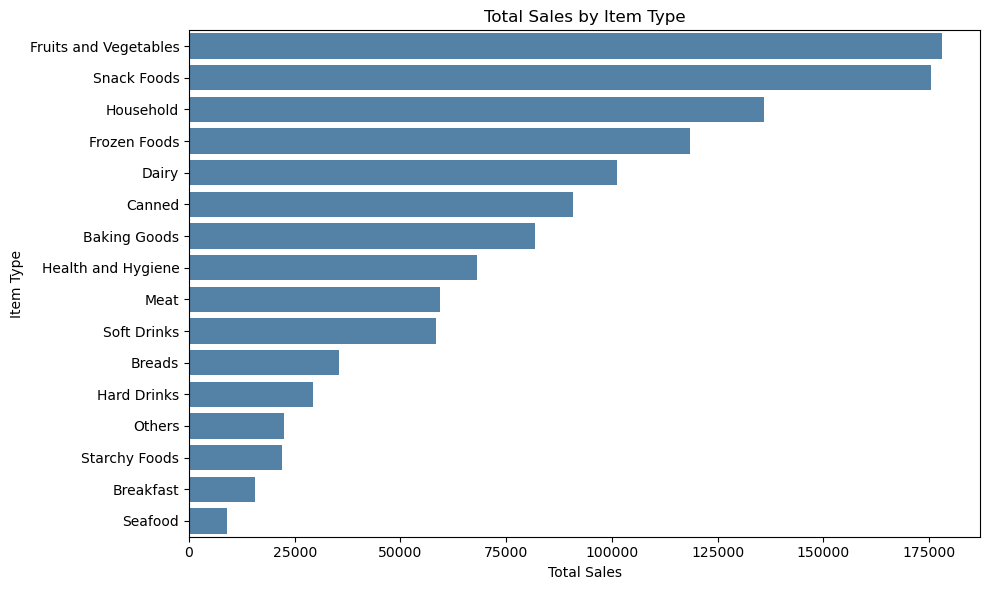

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=sales_by_item_type["sum"],
    y=sales_by_item_type.index,
    color="steelblue"
)

plt.title("Total Sales by Item Type")
plt.xlabel("Total Sales")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

In [47]:
sales_by_outlet_type = (
    df.groupby("Outlet Type")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

display(sales_by_outlet_type.round(2))

,sum,mean,count
Outlet Type,,,
Supermarket Type1,787549.89,141.21,5577
Grocery Store,151939.15,140.29,1083
Supermarket Type2,131477.78,141.68,928
Supermarket Type3,130714.67,139.80,935


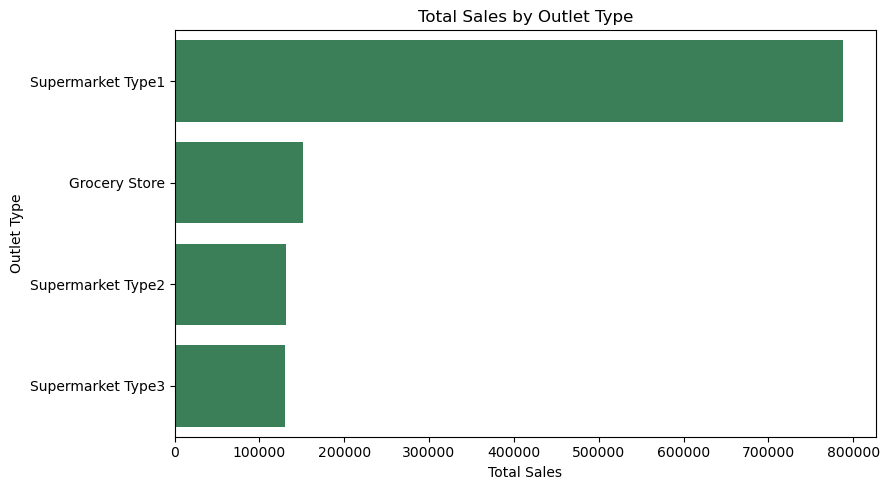

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=sales_by_outlet_type["sum"],
    y=sales_by_outlet_type.index,
    color="seagreen"
)

plt.title("Total Sales by Outlet Type")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Type")
plt.tight_layout()
plt.show()

In [49]:
sales_by_location = (
    df.groupby("Outlet Location Type")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

display(sales_by_location.round(2))

,sum,mean,count
Outlet Location Type,,,
Tier 3,472133.03,140.94,3350
Tier 2,393150.65,141.17,2785
Tier 1,336397.81,140.87,2388


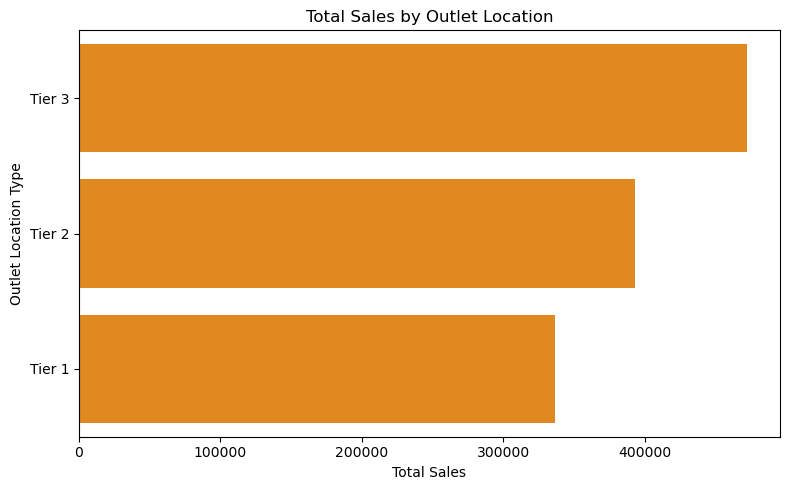

In [50]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sales_by_location["sum"],
    y=sales_by_location.index,
    color="darkorange"
)

plt.title("Total Sales by Outlet Location")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Location Type")
plt.tight_layout()
plt.show()

In [51]:
rating_counts = df["Rating"].value_counts().sort_index()
display(rating_counts)

Rating
1.0     114
1.2       1
1.3       2
1.4       1
1.5      11
1.7       8
1.8       5
1.9       2
2.0      74
2.1       4
2.2       9
2.3      26
2.4      11
2.5      48
2.6      14
2.7      21
2.8      49
2.9      24
3.0     193
3.1      49
3.2      55
3.3     121
3.4      83
3.5     171
3.6     150
3.7     211
3.8     253
3.9     302
4.0    3339
4.1     524
4.2     673
4.3     694
4.4     340
4.5     256
4.6     102
4.7      79
4.8      62
4.9      15
5.0     427
Name: count, dtype: int64

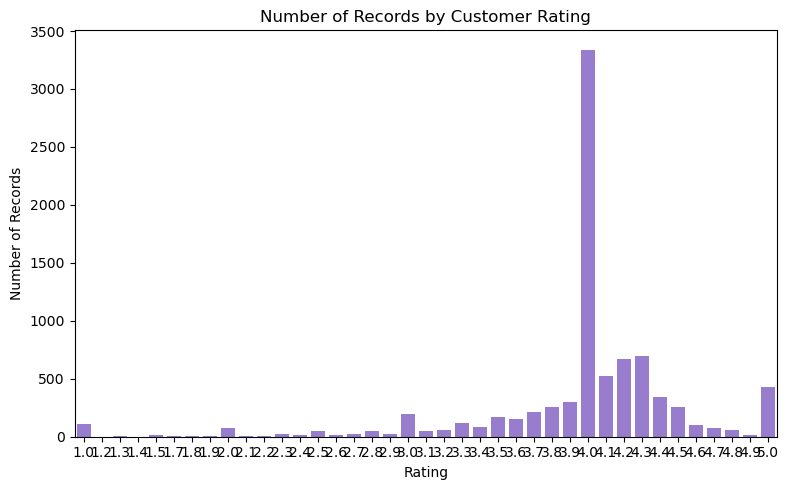

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="mediumpurple"
)

plt.title("Number of Records by Customer Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [53]:
sales_by_rating = (
    df.groupby("Rating")["Sales"]
      .agg(["mean", "sum", "count"])
      .sort_index()
)

display(sales_by_rating.round(2))

,mean,sum,count
Rating,,,
1.0,130.97,14930.77,114
1.2,223.54,223.54,1
1.3,133.08,266.15,2
1.4,172.84,172.84,1
1.5,146.59,1612.53,11
1.7,128.48,1027.86,8
1.8,150.70,753.48,5
1.9,53.17,106.33,2
2.0,137.77,10195.23,74


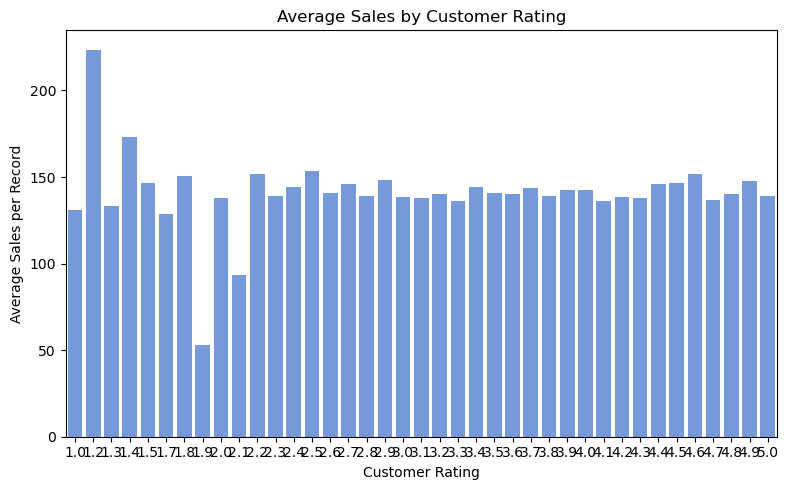

In [54]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sales_by_rating.index,
    y=sales_by_rating["mean"],
    color="cornflowerblue"
)

plt.title("Average Sales by Customer Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Average Sales per Record")
plt.tight_layout()
plt.show()

In [55]:
numeric_columns = ["Item Visibility", "Item Weight", "Sales", "Rating"]

correlations = df[numeric_columns].corr()
display(correlations.round(2))

,Item Visibility,Item Weight,Sales,Rating
Item Visibility,1.00,-0.01,-0.00,0.00
Item Weight,-0.01,1.00,0.03,0.00
Sales,-0.00,0.03,1.00,0.01
Rating,0.00,0.00,0.01,1.00


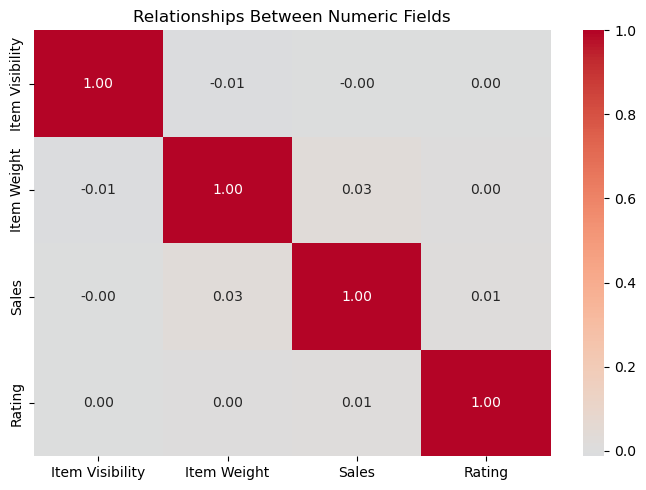

In [56]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Relationships Between Numeric Fields")
plt.tight_layout()
plt.show()

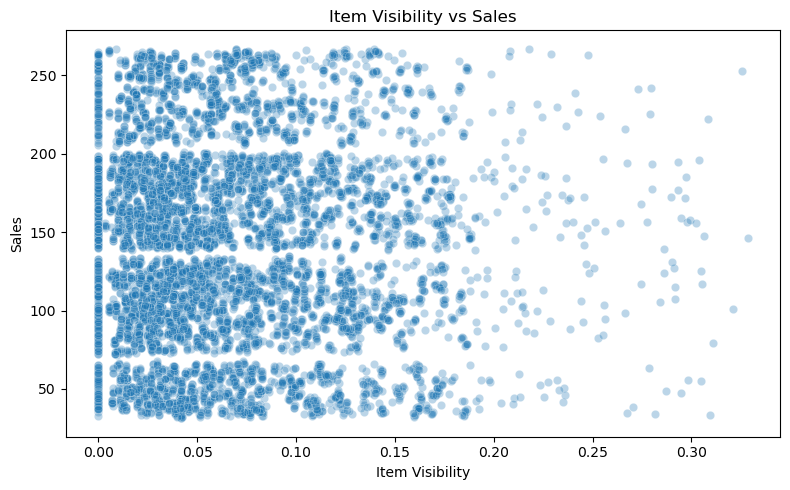

In [57]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Item Visibility",
    y="Sales",
    alpha=0.3
)

plt.title("Item Visibility vs Sales")
plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [58]:
sales_by_outlet_size = (
    df.groupby("Outlet Size")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

display(sales_by_outlet_size.round(2))

,sum,mean,count
Outlet Size,,,
Medium,507895.74,139.88,3631
Small,444794.17,141.70,3139
High,248991.59,142.04,1753


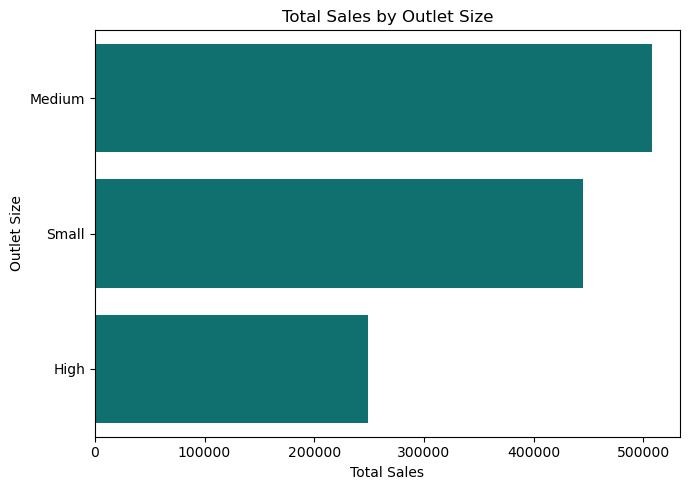

In [59]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=sales_by_outlet_size["sum"],
    y=sales_by_outlet_size.index,
    color="teal"
)

plt.title("Total Sales by Outlet Size")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Size")
plt.tight_layout()
plt.show()

In [60]:
sales_by_fat_content = (
    df.groupby("Item Fat Content")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

display(sales_by_fat_content.round(2))

,sum,mean,count
Item Fat Content,,,
Low Fat,776319.69,140.71,5517
Regular,425361.80,141.50,3006


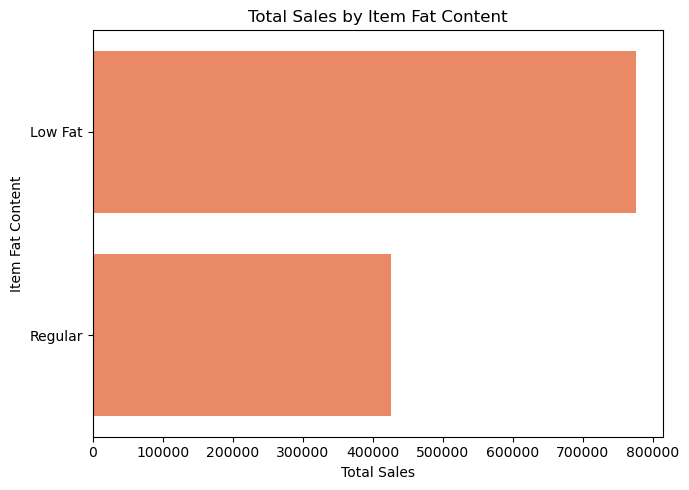

In [61]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=sales_by_fat_content["sum"],
    y=sales_by_fat_content.index,
    color="coral"
)

plt.title("Total Sales by Item Fat Content")
plt.xlabel("Total Sales")
plt.ylabel("Item Fat Content")
plt.tight_layout()
plt.show()

In [62]:
top_10_products = (
    df.groupby("Item Identifier")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

display(top_10_products.to_frame("Total Sales"))

,Total Sales
Item Identifier,
FDU12,2371.0112
FDT07,2306.8970
NCQ06,2294.7126
FDL58,2111.6544
NCB31,2104.7280
FDX31,2104.4622
FDF05,2103.1280
FDR59,2096.5752
FDP28,2087.8488


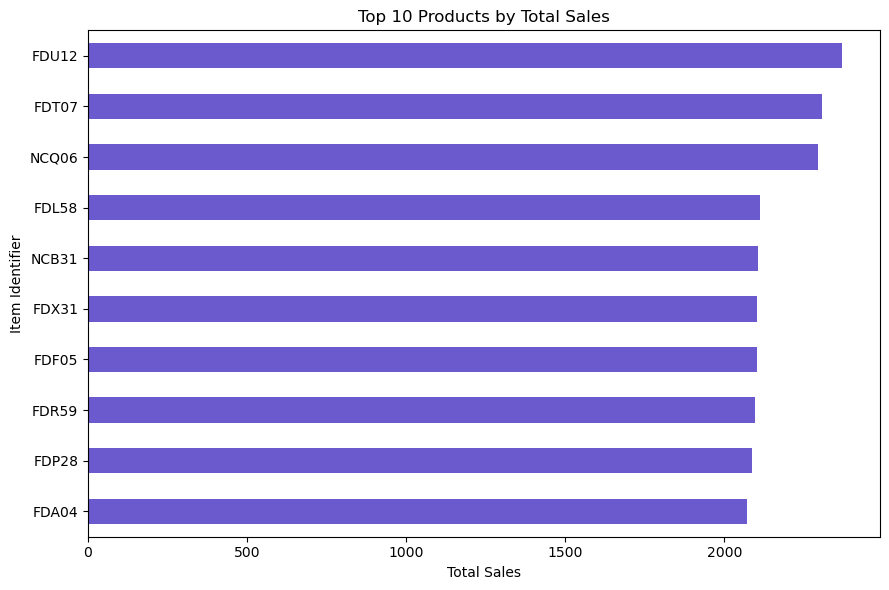

In [63]:
plt.figure(figsize=(9, 6))

top_10_products.sort_values().plot(
    kind="barh",
    color="slateblue"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Item Identifier")
plt.tight_layout()
plt.show()

In [64]:
sales_by_outlet = (
    df.groupby("Outlet Identifier")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

print("Top 10 outlets by total sales:")
display(sales_by_outlet.head(10).round(2))

print("Bottom 10 outlets by total sales:")
display(sales_by_outlet.tail(10).sort_values("sum").round(2))

Top 10 outlets by total sales:


,sum,mean,count
Outlet Identifier,,,
OUT035,133103.91,143.12,930
OUT046,132113.37,142.06,930
OUT013,131809.02,141.43,932
OUT018,131477.78,141.68,928
OUT045,130942.78,140.95,929
OUT027,130714.67,139.80,935
OUT049,130476.86,140.30,930
OUT017,129103.96,139.42,926
OUT010,78131.57,140.78,555


Bottom 10 outlets by total sales:


,sum,mean,count
Outlet Identifier,,,
OUT019,73807.58,139.79,528
OUT010,78131.57,140.78,555
OUT017,129103.96,139.42,926
OUT049,130476.86,140.30,930
OUT027,130714.67,139.80,935
OUT045,130942.78,140.95,929
OUT018,131477.78,141.68,928
OUT013,131809.02,141.43,932
OUT046,132113.37,142.06,930


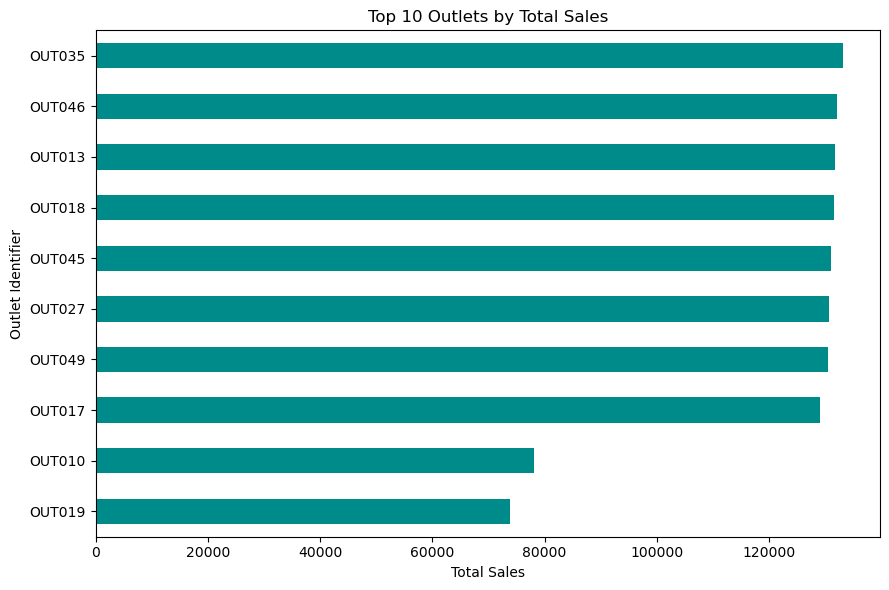

In [65]:
top_10_outlets = sales_by_outlet["sum"].head(10).sort_values()

plt.figure(figsize=(9, 6))
top_10_outlets.plot(kind="barh", color="darkcyan")

plt.title("Top 10 Outlets by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Outlet Identifier")
plt.tight_layout()
plt.show()

In [66]:
sales_by_establishment_year = (
    df.groupby("Outlet Establishment Year")["Sales"]
      .agg(["sum", "mean", "count"])
      .sort_index()
)

display(sales_by_establishment_year.round(2))

,sum,mean,count
Outlet Establishment Year,,,
2011,78131.57,140.78,555
2012,130476.86,140.30,930
2014,131809.02,141.43,932
2015,130942.78,140.95,929
2016,132113.37,142.06,930
2017,133103.91,143.12,930
2018,204522.26,139.80,1463
2020,129103.96,139.42,926
2022,131477.78,141.68,928


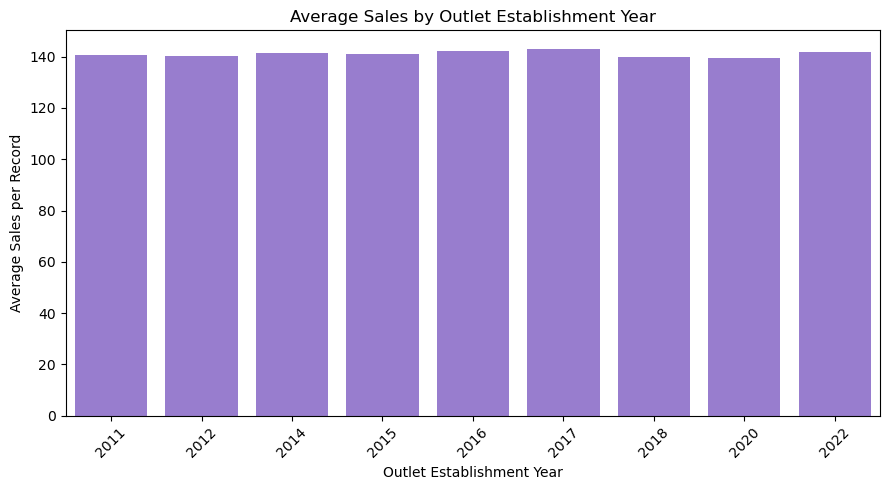

In [67]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=sales_by_establishment_year.index,
    y=sales_by_establishment_year["mean"],
    color="mediumpurple"
)

plt.title("Average Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Average Sales per Record")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

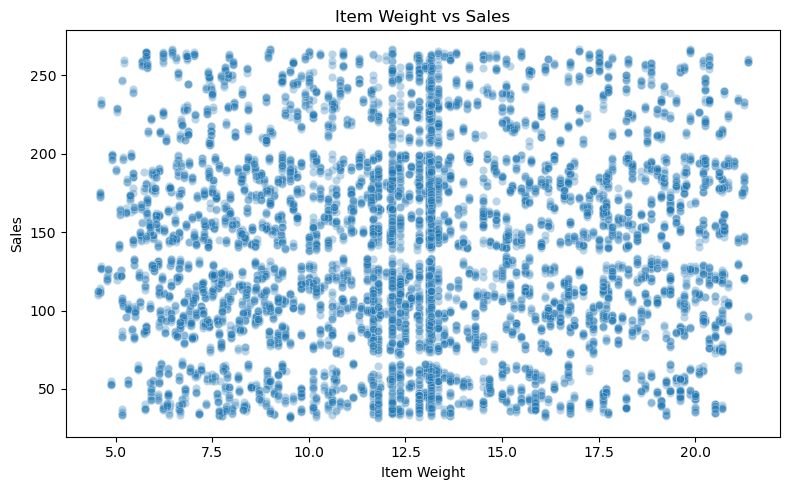

In [76]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Item Weight",
    y="Sales",
    alpha=0.3
)

plt.title("Item Weight vs Sales")
plt.xlabel("Item Weight")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [69]:
highest_sales_records = df.nlargest(10, "Sales")[
    ["Item Identifier", "Item Type", "Outlet Identifier", "Outlet Type", "Sales"]
]

display(highest_sales_records)

,Item Identifier,Item Type,Outlet Identifier,Outlet Type,Sales
183,FDS13,Canned,OUT017,Supermarket Type1,266.8884
3398,FDR25,Canned,OUT046,Supermarket Type1,266.8884
559,FDK51,Dairy,OUT010,Grocery Store,266.6884
1775,NCS29,Health and Hygiene,OUT013,Supermarket Type1,266.6884
3563,NCS29,Health and Hygiene,OUT035,Supermarket Type1,266.5884
5419,FDS13,Canned,OUT019,Grocery Store,266.5884
2720,NCS29,Health and Hygiene,OUT049,Supermarket Type1,266.2884
4977,FDS13,Canned,OUT013,Supermarket Type1,266.1884
6202,FDK51,Dairy,OUT049,Supermarket Type1,266.1884
2131,NCM05,Health and Hygiene,OUT019,Grocery Store,266.0226


In [70]:
lowest_sales_records = df.nsmallest(10, "Sales")[
    ["Item Identifier", "Item Type", "Outlet Identifier", "Outlet Type", "Sales"]
]

display(lowest_sales_records)

,Item Identifier,Item Type,Outlet Identifier,Outlet Type,Sales
5872,DRK12,Soft Drinks,OUT027,Supermarket Type3,31.2900
7880,DRK12,Soft Drinks,OUT013,Supermarket Type1,31.4900
8136,DRK12,Soft Drinks,OUT018,Supermarket Type2,31.8900
7753,FDX59,Breads,OUT013,Supermarket Type1,31.9558
8300,FDG40,Frozen Foods,OUT027,Supermarket Type3,31.9558
7548,FDV28,Frozen Foods,OUT035,Supermarket Type1,32.0558
1541,DRK12,Soft Drinks,OUT017,Supermarket Type1,32.0900
5098,FDU21,Snack Foods,OUT013,Supermarket Type1,32.3558
127,NCO06,Household,OUT046,Supermarket Type1,32.4558
2729,DRK12,Soft Drinks,OUT049,Supermarket Type1,32.4900


In [71]:
outlet_type_location = df.pivot_table(
    values="Sales",
    index="Outlet Type",
    columns="Outlet Location Type",
    aggfunc="mean"
)

display(outlet_type_location.round(2))

Outlet Location Type,Tier 1,Tier 2,Tier 3
Outlet Type,,,
Grocery Store,139.79,NaN,140.78
Supermarket Type1,141.18,141.17,141.43
Supermarket Type2,NaN,NaN,141.68
Supermarket Type3,NaN,NaN,139.80


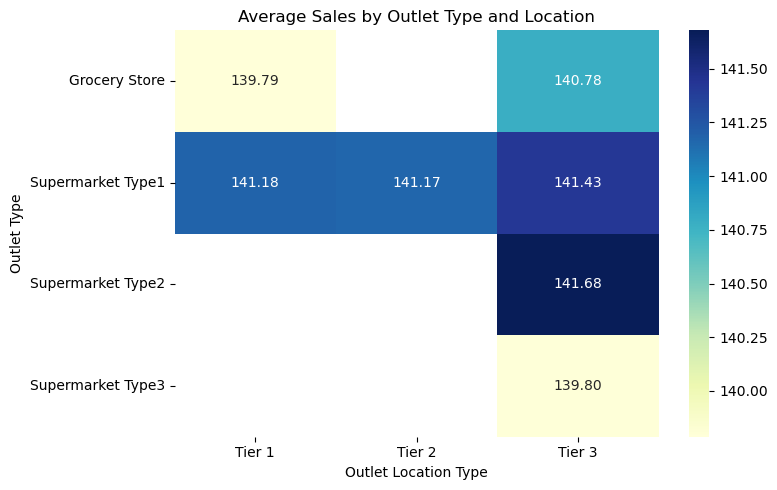

In [72]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    outlet_type_location,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Sales by Outlet Type and Location")
plt.xlabel("Outlet Location Type")
plt.ylabel("Outlet Type")
plt.tight_layout()
plt.show()

In [73]:
print(
    "Top item type:",
    sales_by_item_type["sum"].idxmax(),
    f"({sales_by_item_type['sum'].max():,.2f} total sales)"
)

print(
    "Top outlet type:",
    sales_by_outlet_type["sum"].idxmax(),
    f"({sales_by_outlet_type['sum'].max():,.2f} total sales)"
)

print(
    "Top outlet location:",
    sales_by_location["sum"].idxmax(),
    f"({sales_by_location['sum'].max():,.2f} total sales)"
)

print(
    "Top outlet by average sales:",
    sales_by_outlet["mean"].idxmax(),
    f"({sales_by_outlet['mean'].max():,.2f} average sales per record)"
)

print(
    "Top product identifier:",
    top_10_products.index[0],
    f"({top_10_products.iloc[0]:,.2f} total sales)"
)

Top item type: Fruits and Vegetables (178,124.08 total sales)
Top outlet type: Supermarket Type1 (787,549.89 total sales)
Top outlet location: Tier 3 (472,133.03 total sales)
Top outlet by average sales: OUT035 (143.12 average sales per record)
Top product identifier: FDU12 (2,371.01 total sales)


# Findings and Recommendations

## Key findings
- **Fruits and Vegetables** had the highest total sales among item types, at **178,124.08**.
- **Supermarket Type1** had the highest total sales among outlet types, at **787,549.89**.
- **Tier 3** outlets had the highest total sales among location tiers, at **472,133.03**.
- **OUT035** had the highest average sales per record among outlets, at **143.12**.
- Product **FDU12** had the highest total sales among product identifiers, at **2,371.01**.

## Data quality
- The dataset initially had **1,463** missing Item Weight values. I filled them using the median weight for the same Item Type.
- I standardized inconsistent Item Fat Content labels.
- I found **no exact duplicate rows**.

## Recommendations
- Monitor stock availability for Fruits and Vegetables and the leading products. The dataset has no cost or profit fields, so high sales alone do not confirm high profitability.
- Review the product mix and sales records for Supermarket Type1 and Tier 3 outlets before changing inventory plans. Their total sales may also reflect how many records are associated with them.
- Investigate OUT035’s high average sales per record and compare its product mix with other outlets before drawing conclusions about why it performs well.
- Collect transaction dates, quantities, and costs in future data so the business can analyze sales trends, units sold, and profit.

## Limitation
- This dataset has no transaction dates, quantities, or costs, so this analysis cannot show monthly sales trends, units sold, or profit.